# Coordinate geometry laboratory

Optional companion to the [Cartesian plane chapter](../subjects/geometry/coordinate-geometry/cartesian-plane.md). Read the mathematics there first. This notebook contains saved outputs and can also be run from top to bottom.

**Assumptions:** real coordinates in an orthonormal Euclidean plane; both axes use the same length unit. Floating-point values draw the plots. SymPy checks exact algebra later. Programming is optional.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

## Change two points

Edit only `A` and `B`, then rerun the remaining cells. Each array contains `[x, y]`. Before running, predict the distance and midpoint. For the supplied points the changes are 6 and 8, so the length is 10 and the midpoint is (4, 6).

In [2]:
A = np.array([1.0, 2.0])
B = np.array([7.0, 10.0])
for point in (A, B):
    if point.shape != (2,) or not np.isfinite(point).all():
        raise ValueError('Each point must contain two finite real coordinates.')
change = B - A
distance = np.hypot(*change)
midpoint = (A + B) / 2
print('Displacement:', change)
print('Distance (coordinate units):', distance)
print('Midpoint:', midpoint)
assert np.isclose(np.hypot(*(midpoint - A)), distance / 2)
assert np.isclose(np.hypot(*(B - midpoint)), distance / 2)

Displacement: [6. 8.]
Distance (coordinate units): 10.0
Midpoint: [4. 6.]


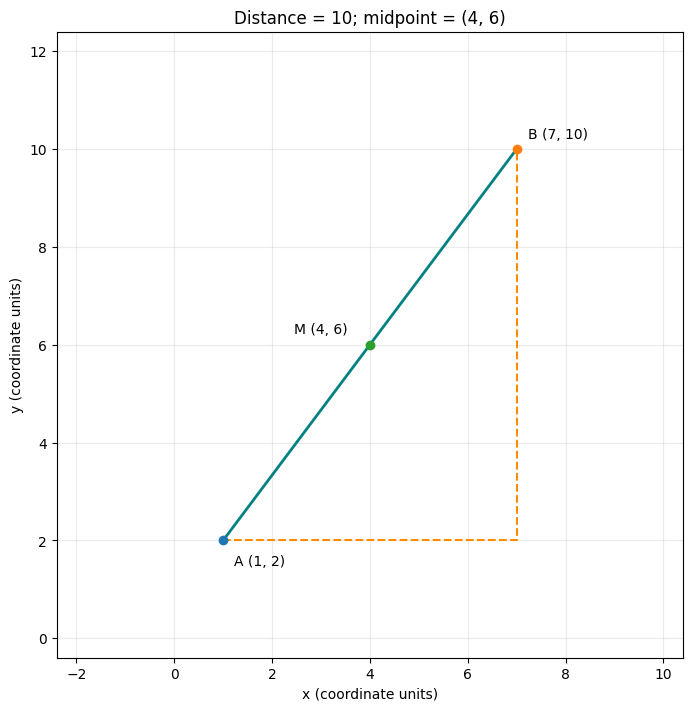

In [3]:
fig, ax = plt.subplots(figsize=(7, 7), layout='constrained')
ax.plot([A[0], B[0]], [A[1], B[1]], color='teal', linewidth=2)
ax.plot([A[0], B[0], B[0]], [A[1], A[1], B[1]], '--', color='darkorange')
for name, point, offset in [('A', A, (8, -18)), ('B', B, (8, 8)), ('M', midpoint, (-55, 8))]:
    ax.scatter(*point, zorder=3)
    ax.annotate(f'{name} ({point[0]:g}, {point[1]:g})', point, xytext=offset, textcoords='offset points')
span = max(np.ptp(np.array([A, B]), axis=0).max(), 1.0)
center = midpoint
ax.set(xlim=(center[0] - 0.8*span, center[0] + 0.8*span),
       ylim=(center[1] - 0.8*span, center[1] + 0.8*span),
       xlabel='x (coordinate units)', ylabel='y (coordinate units)',
       title=f'Distance = {distance:.6g}; midpoint = ({midpoint[0]:g}, {midpoint[1]:g})')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.25)
plt.show()

## A line meets a circle

This is a separate fixed example: $x^2+y^2=25$ and $y=x+1$, matching exercise CG-07. Here $x,y$ are real coordinates. Substitution gives $2x^2+2x-24=0$, whose roots are $-4$ and $3$. SymPy keeps the intersection coordinates exact. The plot samples the ideal circle at finitely many angles.

In [4]:
x, y = sp.symbols('x y', real=True)
intersections = sp.solve([x**2 + y**2 - 25, y - x - 1], (x, y))
print('Exact intersections:', intersections)
assert set(intersections) == {(-4, -3), (3, 4)}
for px, py in intersections:
    assert sp.simplify(px**2 + py**2 - 25) == 0
    assert sp.simplify(py - px - 1) == 0

Exact intersections: [(-4, -3), (3, 4)]


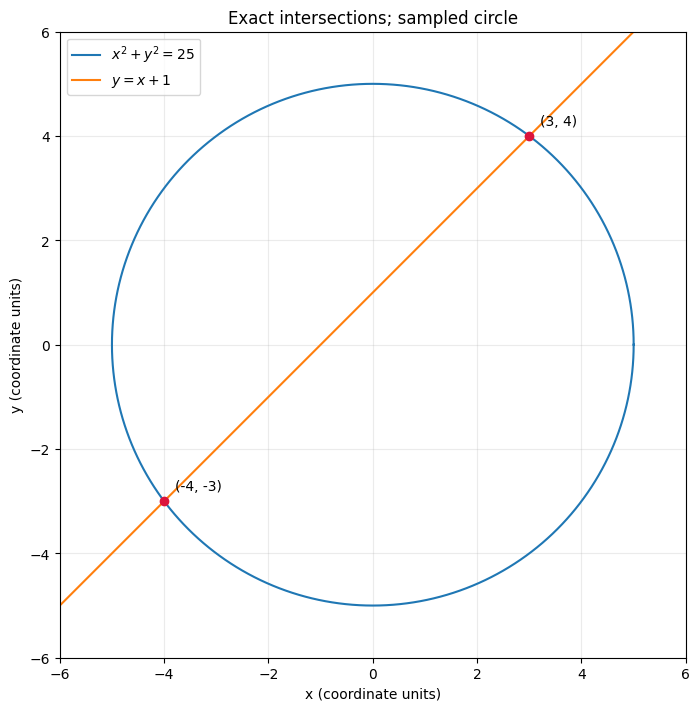

In [5]:
theta = np.linspace(0, 2*np.pi, 721)
xx = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(7, 7), layout='constrained')
ax.plot(5*np.cos(theta), 5*np.sin(theta), label=r'$x^2+y^2=25$')
ax.plot(xx, xx+1, label=r'$y=x+1$')
for px, py in intersections:
    ax.scatter(float(px), float(py), color='crimson', zorder=3)
    ax.annotate(f'({px}, {py})', (float(px), float(py)), xytext=(8, 8), textcoords='offset points')
ax.set(xlim=(-6, 6), ylim=(-6, 6), xlabel='x (coordinate units)',
       ylabel='y (coordinate units)', title='Exact intersections; sampled circle')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Try and explain

1. Set A=(3,-2) and B=(3,5). Why can the distance still be calculated when the slope is undefined?
2. Swap A and B. Which signed quantities change, and which results stay the same?
3. Set A=B. What happens to distance and midpoint? Why do these endpoints no longer define a unique line?

**Answers:** (1) Only the vertical change contributes, so the distance is 7; slope would divide by zero. (2) Both displacement components reverse sign, but distance and midpoint stay unchanged. (3) Distance is zero and midpoint is the common point; infinitely many lines pass through it.

The assertions check encoded examples, not every mathematical claim. [Return to the chapter](../subjects/geometry/coordinate-geometry/cartesian-plane.md).